# p04_supplier_resolution — which supplier ids are the same firm?

A `supplier_id` is a registration, not a firm: the same company is often registered several times, with names spelled differently ("ERNST & YOUNG LLP", "ERNST AND YOUNG LLP", "ERNST & YOUNG (EY) LLP, INDIA"). This notebook groups supplier ids into **supplier entities** with explainable rules, measures how well that works against labelled pairs, and publishes:

| Table | Grain | Key |
|---|---|---|
| `proc_silver.supplier_entities` | one resolved firm (or anonymised individual) | `supplier_entity_id` |
| `proc_silver.supplier_entity_map` | one supplier id, with its entity | `supplier_id` |
| `proc_silver.supplier_match_links` | one pair of name records linked by a name rule, with the scores | `record_a, record_b` |

%md-sandbox
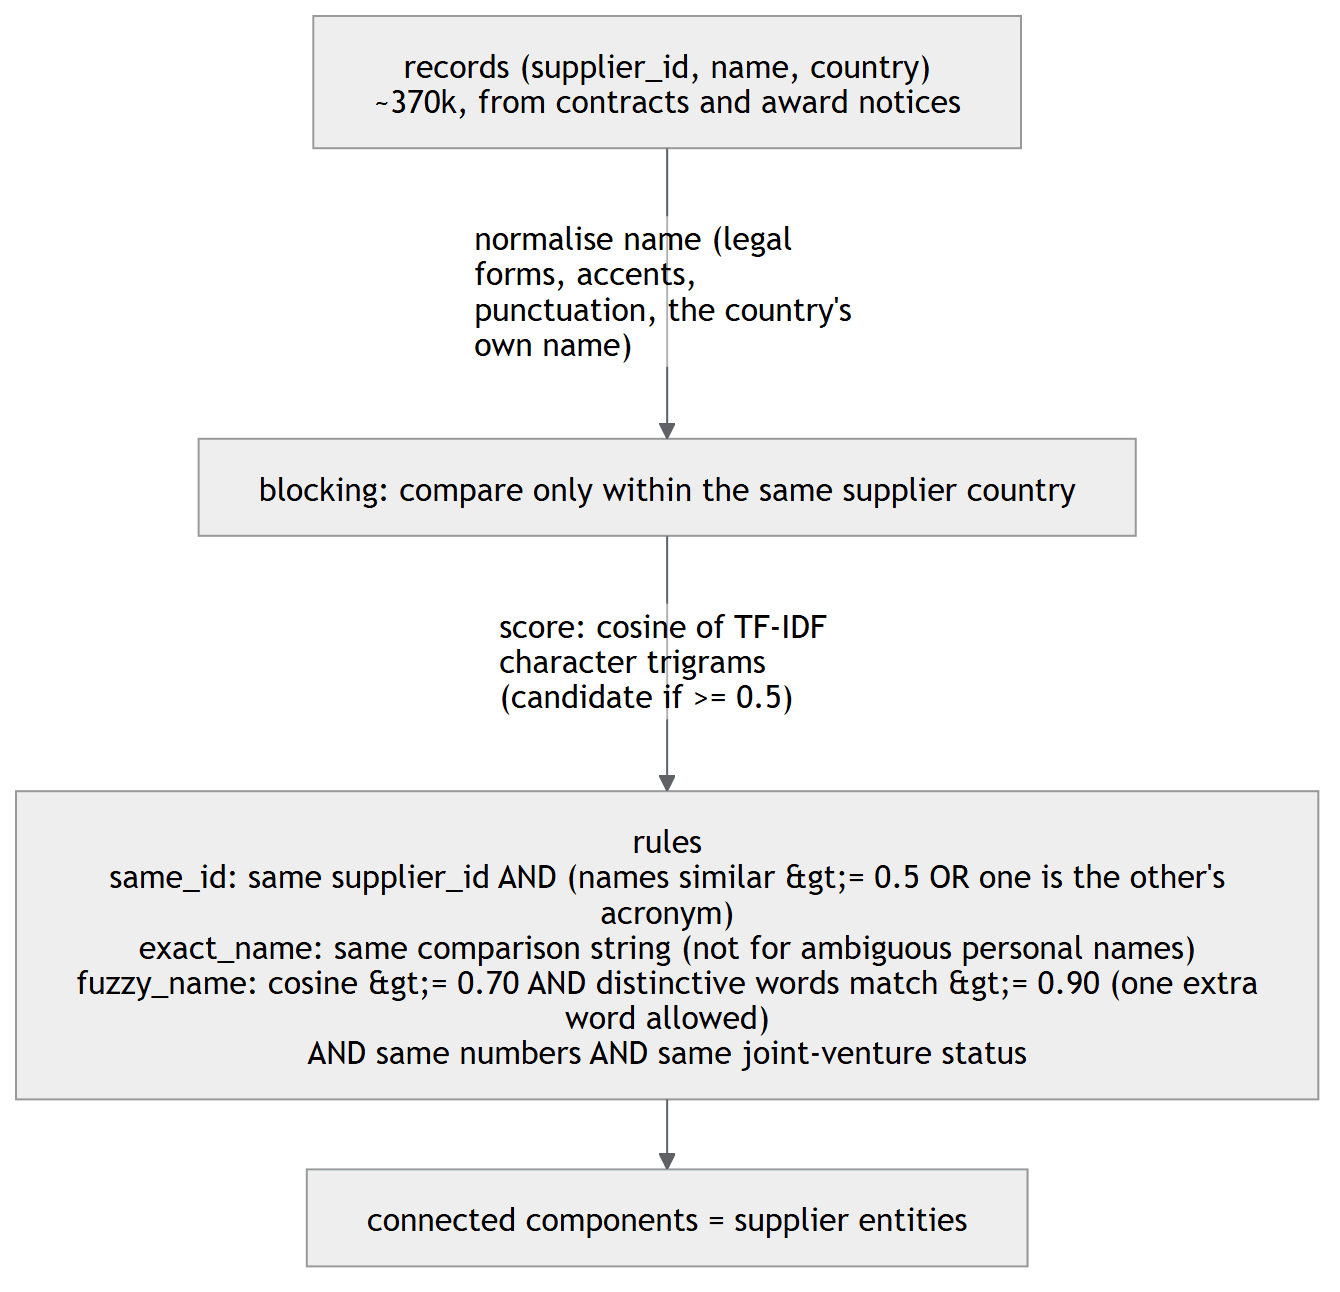

<details><summary>Diagram source (Mermaid)</summary>

<pre><code>---
config:
  layout: elk
  htmlLabels: false
  flowchart:
    htmlLabels: false
    wrappingWidth: 600
---
flowchart TD
    rec["records (supplier_id, name, country)&lt;br/&gt;~370k, from contracts and award notices"]
    blk["blocking: compare only within the same supplier country"]
    rules["rules&lt;br/&gt;same_id: same supplier_id AND (names similar &gt;= 0.5 OR one is the other's acronym)&lt;br/&gt;exact_name: same comparison string (not for ambiguous personal names)&lt;br/&gt;fuzzy_name: cosine &gt;= 0.70 AND distinctive words match &gt;= 0.90 (one extra word allowed)&lt;br/&gt;AND same numbers AND same joint-venture status"]
    cc["connected components = supplier entities"]
    rec --&gt;|"normalise name (legal forms, accents, punctuation, the country's own name)"| blk
    blk --&gt;|"score: cosine of TF-IDF character trigrams (candidate if &gt;= 0.5)"| rules
    rules --&gt; cc
</code></pre>

</details>

No language model is used: every link can be explained by the rule and the scores stored with it.

## Key design decisions

| Decision | Rationale | Evidence |
|---|---|---|
| A shared `supplier_id` links two names only if they are similar (cosine >= 0.5) or one is the other's acronym; otherwise the id is split and follows its most used name | "Different id = different firm" is false; "same id = same firm" is only mostly true | 6,648 names appear under more than one id; about 97% of multi-name ids are spelling variants; the rest include acronyms or translations ("SAHE" = "SOCIETE AFRICAINE D'HYDRAULIQUE ET D'ELECTRICITE") and two parties under one id ("SANJEEV KUMAR" / "SUSHIL KUMAR"); trusting every shared id chained nine firms (ENTREPRISE SATU-SA, Niger, with BAANA, EGAM, ENISAB, ...) into one entity of 77 records |
| Similarity = cosine of TF-IDF weighted character trigrams, compared only within the same supplier country (blocking); Jaro-Winkler and token-set ratio kept as explanatory columns only | Trigrams tolerate typos and spacing, cosine ignores word order, TF-IDF down-weights words every supplier uses; blocking keeps the work small and matches how firms register | Variants are typos ("PRICEWTERHOUSECOOPERS"), spacing ("ABCCONSULT"), word order and extra words ("(DWP GROUP)"); Jaro-Winkler rewards a shared prefix ("CONSTRUCTION ..."); token-set ratio scores 1.0 on containment ("AGRITCHAD" vs "GROUPEMENT SETI AGRITCHAD"); minutes for 370k records on one node; "PWC ALBANIA" and "PRICEWATERHOUSECOOPERS" (Poland) are different legal entities |
| A fuzzy link must also agree on the distinctive words (words rare among that country's supplier names) | A plain cosine threshold chains different firms into giant clusters | At 0.6 the largest cluster had 2,540 records, at 0.7 still 433 (shared generic Vietnamese phrases; 12 provincial "LAND REGISTRATION OFFICE OF <province> PROVINCE"s); in the award-names prototype the check raised precision on the labelled pairs from 0.73 to 1.00 at the same threshold and reduced the largest cluster from 433 records to a real firm |
| Common personal names get no name links: a personal-looking name whose every word also appears in more than 3 other names of that country (names without its remaining words); fuzzy links need the distinctive words to match at 0.9 | Identical common personal names often denote different people; rare personal names may still match exactly | One third of the records look like personal names; "AJAY KUMAR" appears under 24 ids; the labelled "ARUN KUMAR" pair are contractors in two different forest divisions; "UASSI MWEMA" (Comoros) is one contractor in two contracts of one project; counting only names without the other words keeps "SEC DIARRA" (an audit firm with 40 ids) from looking common; "KARANJEET" / "CHARANJEET" stay apart |
| Threshold 0.70 (trade-off in the section 4 sweep); the strict word match allows one extra word on the longer side, drops "(LEAD)" markers, and gives singular and plural the same generic status | The strict match rejected true variants | 100 labelled pairs from every similarity band (0.3 to 1.0) plus a random audit of 40 produced fuzzy links, both labelled by an AI agent (sections 4 and 7); p15 three-tier relabelling: precision 1.00 (95% CI 0.90-1.00), recall 0.90 (0.77-0.96) on 97 decided pairs; rejected variants included "ECONOMIC CONSULTING ASSOCIATES LIMITED (ECA)", "PRICEWATERHOUSECOOPERS ... (PWC INDIA)", "OMNI SOLUTION TECHNOLOGIE" vs "OMNI SOLUTIONS TECHNOLOGIES" |

Limitations: the 100 labelled pairs also chose the threshold, so the random link audit in section 7 is the less biased precision estimate.

Full reasoning: docs/decision_log.md

## Setup

**What:** libraries, shared helpers, the match rules and the label files (in `../data`, versioned with the code).

**Why:** the thresholds are named constants in one place; the labels live next to the code so anyone can re-check or extend them.

In [ ]:
%pip install -q rapidfuzz unidecode

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [ ]:
dbutils.library.restartPython()

In [ ]:
%run ./proc_common

In [ ]:
import hashlib
import json
from dataclasses import replace

import numpy as np
from pyspark.sql import Window

from proc_intel.resolution import MatchRules, decide, prepare_records, resolve, score_candidates
from proc_intel.similarity import char_ngram_tfidf, explain_pair, precision_recall, score_band_counts, wilson_interval

RULES = MatchRules(fuzzy_threshold=0.70, candidate_floor=0.50, same_id_min_cosine=0.50, ambiguous_max_others=3,
                   generic_min_df=10, generic_share=0.005, core_min_similarity=0.90)
THRESHOLDS = [0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
LABELS_PATH = os.path.join(os.path.dirname(SRC_DIR), "data", "supplier_pair_labels.csv")
AUDIT_PATH = os.path.join(os.path.dirname(SRC_DIR), "data", "supplier_link_audit.csv")
AUDIT_SIZE = 40
INDIVIDUAL_ID = "^[0-9a-f]{16}$"

## 1. Name records

**What:** every distinct (supplier id, name, country) seen on a contract or in an award notice, with how often it is used (`n_uses`), excluding anonymised individual consultants (hashed id, no name) and the one award row without an id.

**Why:** an id can carry several spellings and, rarely, several countries; each combination is compared on its own and the shared id ties them together again. Award-notice spellings add evidence for winners and bring in bidders who never won.

In [ ]:
named = (spark.table(f"{SILVER}.contract_suppliers")
         .select("supplier_id", F.col("supplier_name").alias("name"), F.col("supplier_country_code").alias("country_code"))
         .unionByName(spark.table(f"{SILVER}.notice_bidders")
                      .select("supplier_id", F.col("firm_name").alias("name"), F.col("firm_country_code").alias("country_code")))
         .filter(~F.col("supplier_id").rlike(INDIVIDUAL_ID) & ~F.col("supplier_id").startswith("NOID-"))
         .filter(F.length(F.trim("name")) > 0)
         .groupBy("supplier_id", "name", "country_code").agg(F.count("*").alias("n_uses")))
records_raw = named.toPandas()
country_names = {r.country_code: r.country_name for r in spark.table(f"{SILVER}.dim_country").collect()}
records = prepare_records(records_raw, RULES, country_names)
print(f"records: {len(records):,} | supplier ids: {records['supplier_id'].nunique():,} | "
      f"distinct raw names: {records['name'].nunique():,} | distinct comparison strings: {records['comparison'].nunique():,}")
print(f"ambiguous personal-name records: {int(records['ambiguous_person'].sum()):,} | consortium names: {int(records['is_consortium'].sum()):,}")
display(records.sample(10, random_state=1)[["supplier_id", "name", "country_code", "comparison", "distinctive", "ambiguous_person"]])

records: 369,560 | supplier ids: 344,254 | distinct raw names: 300,693 | distinct comparison strings: 268,126
ambiguous personal-name records: 18,661 | consortium names: 8,350


supplier_id | name                                                             | country_code | comparison                                           | distinctive                         | ambiguous_person
------------+------------------------------------------------------------------+--------------+------------------------------------------------------+-------------------------------------+-----------------
463881      | ROUSANT INTERNATIONAL LIMITED                                    | CN           | ROUSANT INTERNATIONAL                                | ROUSANT                             | False           
582632      | SOMTECH ENGINEERING & CONSTRUCTION COMPANY                       | SO           | SOMTECH ENGINEERING AND CONSTRUCTION                 | SOMTECH                             | False           
791649      | ASCOMA                                                           | None         | ASCOMA                                               | ASCOMA                   

## 2. How consistent is `supplier_id`?

**What:** for every id with more than one name record, the lowest trigram cosine between its spellings; how many ids look like spelling variants (>= 0.5), how many carry a dissimilar name, and how many span several countries. Then the most dissimilar examples.

**Why:** this is the evidence for Step 1 — the id is used as a link, so its failure rate should be known.

In [ ]:
matrix = char_ngram_tfidf(records["comparison"].tolist())
multi = records[records["supplier_id"].duplicated(keep=False)]
id_rows = []
for sid, grp in multi.groupby("supplier_id"):
    idx = grp.index.to_numpy()
    sims = (matrix[idx] @ matrix[idx].T).toarray()
    id_rows.append({"supplier_id": sid, "min_cosine": float(sims.min()), "names": sorted(set(grp["name"])),
                    "countries": sorted(set(grp["country_code"].dropna()))})
id_consistency = pd.DataFrame(id_rows)
n_ids = records["supplier_id"].nunique()
print(f"ids with one name record: {n_ids - len(id_consistency):,} of {n_ids:,}")
print(f"ids with several records: {len(id_consistency):,} | spelling variants (min cosine >= 0.5): "
      f"{int((id_consistency['min_cosine'] >= 0.5).sum()):,} | with a dissimilar name: "
      f"{int((id_consistency['min_cosine'] < 0.5).sum()):,} | spanning >1 country: "
      f"{int((id_consistency['countries'].map(len) > 1).sum()):,}")
display(id_consistency.sort_values("min_cosine").head(15))

ids with one name record: 319,493 of 344,254
ids with several records: 24,761 | spelling variants (min cosine >= 0.5): 24,097 | with a dissimilar name: 664 | spanning >1 country: 28


supplier_id | min_cosine | names                                                                                                                                       | countries
------------+------------+---------------------------------------------------------------------------------------------------------------------------------------------+----------
657407      | 0.0        | ['SAHE', "SOCIETE AFRICAINE D'HYDRAULIQUE ET D'ELECTRICITE-SARL"]                                                                           | ['SN']   
732550      | 0.0        | ['RETAIL CAPACITY DEVELOPMENT PTY LTD', 'TESAE TRADING']                                                                                    | ['AU']   
179274      | 0.0        | ['CABINET ENVAL', "LE CABINET CATANA EXPERTISE CONSEIL SOCIETE D'EXPERTISE COMPTABLE ET COMMISSARIAT AUX COMPTES CATANA EXPERTISE CONSEIL"] | ['CI']   
462334      | 0.0        | ['GRUPO GTD PERU SAC', 'NETLINE PERU S.A.']                                   

## 3. Candidate pairs and features

**What:** all pairs in the same country with trigram cosine >= 0.5 (plus pairs with an identical comparison string), with the features the rules use: same id, same key, same numbers, same joint-venture status, ambiguous personal name, and the word-by-word match of the distinctive words.

**Why:** the features are computed once; the threshold sweep below only re-applies the rules.

In [ ]:
pairs = score_candidates(records, RULES)
print(f"candidate pairs: {len(pairs):,} (same id: {int(pairs['same_id'].sum()):,}, identical key: {int(pairs['same_key'].sum()):,})")
display(pairs.assign(band=(np.floor(pairs["cosine"] * 10) / 10).clip(upper=1.0))
        .groupby("band").agg(pairs=("i", "size"), same_id_share=("same_id", "mean"), same_key_share=("same_key", "mean"))
        .reset_index())

candidate pairs: 3,893,128 (same id: 25,918, identical key: 241,182)


band | pairs   | same_id_share          | same_key_share        
-----+---------+------------------------+-----------------------
0.0  | 139     | 0.935251798561151      | 0.06474820143884892   
0.1  | 131     | 0.9007633587786259     | 0.09923664122137404   
0.2  | 157     | 0.8598726114649682     | 0.14012738853503184   
0.3  | 163     | 0.803680981595092      | 0.20245398773006135   
0.4  | 286     | 0.6433566433566433     | 0.3706293706293706    
0.5  | 2606567 | 0.00011777943939288727 | 0.00026778517490630394
0.6  | 724728  | 0.0009024075239262179  | 0.0022711969180161384 
0.7  | 191565  | 0.006159789105525539   | 0.012768511993318195  
0.8  | 81983   | 0.025724845394776964   | 0.05635314638400644   
0.9  | 84290   | 0.06175109740182703    | 0.527690117451655     
1.0  | 203119  | 0.07761460030819371    | 0.9211841334390185    

## 4. Evaluation on 100 labelled pairs, and the threshold

**What:** the labelled pairs (`data/supplier_pair_labels.csv`) were drawn from candidate pairs of *different* ids in every cosine band from 0.3 to 1.0 and labelled by an AI agent during the build, by reading the names and, where unclear, the contracts (project, description, place). These build labels are what this notebook runs on; the final labels of the same pairs come from the three-tier escalation in p15, which agrees with them on 96 of 100 pairs. For each threshold the full pipeline is run and a pair counts as "predicted same" when both records end up in the same entity, so chained merges are evaluated too.
- *unweighted*: every labelled pair counts once.
- *band-weighted*: each pair stands for its band's share of all candidate pairs (the sample over-represents rare high-score bands, so this is closer to the population).

**Why:** this is the test that chooses the threshold and shows the precision/recall trade-off. Wilson intervals show how much 100 labels can and cannot say.

In [ ]:
labels = pd.read_csv(LABELS_PATH, dtype={"supplier_id_a": str, "supplier_id_b": str}, keep_default_na=False)
position = {(s, n, c): i for i, (s, n, c) in enumerate(zip(records["supplier_id"], records["name"],
                                                            records["country_code"].fillna("")))}
labels["i"] = [position.get(k) for k in zip(labels["supplier_id_a"], labels["name_a"], labels["country_code"])]
labels["j"] = [position.get(k) for k in zip(labels["supplier_id_b"], labels["name_b"], labels["country_code"])]
assert labels[["i", "j"]].notna().all().all(), "a labelled record is missing from the records"
labels["cosine"] = [float((matrix[i] @ matrix[j].T).toarray()[0, 0]) for i, j in zip(labels["i"], labels["j"])]
labels["band"] = (np.floor(labels["cosine"] * 10) / 10).clip(upper=1.0)

# band populations: pairs of different ids down to cosine 0.3 (the lowest sampled band), counted chunk by chunk
band_population = pd.Series(score_band_counts(matrix, records["block"].tolist(), records["supplier_id"].tolist(), 0.3))
labels["band"] = labels["band"].round(2)
labels["weight"] = labels["band"].map(band_population) / labels["band"].map(labels["band"].value_counts())
display(pd.DataFrame({"pairs_in_band": band_population, "labelled": labels["band"].value_counts(),
                      "share_same_entity": labels.groupby("band")["label_same_entity"].mean().round(2)}).sort_index())
y = labels["label_same_entity"].astype(bool).tolist()

sweep = []
for threshold in THRESHOLDS:
    rules = replace(RULES, fuzzy_threshold=threshold)
    entity = resolve(records, pairs, decide(pairs, rules))
    predicted = [entity[i] == entity[j] for i, j in zip(labels["i"], labels["j"])]
    raw, weighted = precision_recall(y, predicted), precision_recall(y, predicted, labels["weight"].tolist())
    sizes = entity.value_counts()
    sweep.append({"threshold": threshold, "precision": raw["precision"], "recall": raw["recall"],
                  "tp": raw["tp"], "fp": raw["fp"], "fn": raw["fn"],
                  "weighted_precision": weighted["precision"], "weighted_recall": weighted["recall"],
                  "entities": entity.nunique(), "largest_entity_records": int(sizes.iloc[0])})
sweep = pd.DataFrame(sweep)
display(sweep.round(3))

chosen = sweep.set_index("threshold").loc[RULES.fuzzy_threshold]
p_low, p_high = wilson_interval(int(chosen["tp"]), int(chosen["tp"] + chosen["fp"]))
r_low, r_high = wilson_interval(int(chosen["tp"]), int(chosen["tp"] + chosen["fn"]))
print(f"chosen threshold {RULES.fuzzy_threshold}: precision {chosen['precision']:.3f} (95% CI {p_low:.2f}-{p_high:.2f}), "
      f"recall {chosen['recall']:.3f} (95% CI {r_low:.2f}-{r_high:.2f}) on {len(labels)} labelled pairs "
      f"({int(sum(y))} same-entity)")

pairs_in_band | labelled | share_same_entity
--------------+----------+------------------
None          | 4        | 0.0              
None          | 2        | 0.0              
18956628.0    | 8        | 0.0              
8058611.0     | 8        | 0.0              
2606260.0     | 11       | 0.0              
724074.0      | 12       | 0.0              
190385.0      | 11       | 0.27             
79874.0       | 13       | 0.69             
79170.0       | 19       | 0.95             
187269.0      | 12       | 0.83             

threshold | precision | recall | tp | fp | fn | weighted_precision | weighted_recall | entities | largest_entity_records
----------+-----------+--------+----+----+----+--------------------+-----------------+----------+-----------------------
0.6       | 0.973     | 0.9    | 36 | 1  | 4  | 0.987              | 0.9             | 258340   | 120                   
0.65      | 0.973     | 0.9    | 36 | 1  | 4  | 0.987              | 0.9             | 259860   | 120                   
0.7       | 0.973     | 0.9    | 36 | 1  | 4  | 0.987              | 0.9             | 261576   | 120                   
0.75      | 0.971     | 0.85   | 34 | 1  | 6  | 0.985              | 0.798           | 263743   | 119                   
0.8       | 0.971     | 0.85   | 34 | 1  | 6  | 0.985              | 0.798           | 266370   | 119                   
0.85      | 0.97      | 0.8    | 32 | 1  | 8  | 0.984              | 0.762           | 269415   | 119                   
0.9       | 0.966     | 0.7    |

chosen threshold 0.7: precision 0.973 (95% CI 0.86-1.00), recall 0.900 (95% CI 0.77-0.96) on 100 labelled pairs (40 same-entity)


## 5. Resolve at the chosen threshold

**What:** applies the rules at 0.70, groups records into connected components, and lists which labelled pairs the pipeline still gets wrong.

**Why:** the misses show the price of the precision-first rules (typos inside distinctive words, personal names, owner/brand names).

In [ ]:
rule = decide(pairs, RULES)
records["supplier_entity_id"] = resolve(records, pairs, rule)
labels["predicted_same"] = [records.at[i, "supplier_entity_id"] == records.at[j, "supplier_entity_id"]
                            for i, j in zip(labels["i"], labels["j"])]
print("links by rule:", rule.value_counts().to_dict())
display(labels.loc[labels["predicted_same"] != labels["label_same_entity"].astype(bool),
                   ["pair_id", "name_a", "name_b", "country_code", "cosine", "label_same_entity", "note"]])

links by rule: {'exact_name': 198024, 'fuzzy_name': 59269, 'same_id': 25234}


pair_id | name_a                                    | name_b                                    | country_code | cosine             | label_same_entity | note                                                         
--------+-------------------------------------------+-------------------------------------------+--------------+--------------------+-------------------+--------------------------------------------------------------
44      | VIMA SERV                                 | VIMA                                      | MG           | 0.7534597516059875 | 1                 | probable: both goods suppliers in Madagascar, SERV = services
60      | CPCS TRANSCOM LIMITED                     | CPCS TRANSCOM LIMITD (CPCS)               | CA           | 0.8402372002601624 | 1                 |                                                              
70      | ANHUI ANZE THINK TANK CONSULTING CO., LTD | ANHUI ANCE THINK TANK CONSULTING CO., LTD | CN           | 0.8621529340744019 | 1 

## 6. Examples: good merges and hard cases

**What:**
- the largest entities with their spellings (correct merges should dominate);
- pairs the distinctive-word check **rejected** despite a high cosine (the chaining problem of Step 3);
- the most frequent ambiguous personal names that were deliberately not merged.

**Why:** numbers alone hide *what kind* of mistakes remain; these tables make the behaviour reviewable.

In [ ]:
sizes = records.groupby("supplier_entity_id").agg(records=("name", "size"), ids=("supplier_id", "nunique"),
                                                 country=("country_code", "first"),
                                                 spellings=("name", lambda s: sorted(set(s))[:6]))
display(sizes.sort_values("records", ascending=False).head(12).reset_index())

rejected = pairs[(pairs["cosine"] >= 0.85) & ~pairs["same_key"] & ~pairs["same_id"] & ~pairs["ambiguous"]
                 & (pairs["core_similarity"] < RULES.core_min_similarity)]
print(f"high-cosine pairs (>= 0.85) rejected by the distinctive-word check: {len(rejected):,}")
display(rejected.sample(min(12, len(rejected)), random_state=3).assign(
    name_a=lambda d: records.loc[d["i"], "name"].to_numpy(), name_b=lambda d: records.loc[d["j"], "name"].to_numpy(),
    distinctive_a=lambda d: records.loc[d["i"], "distinctive"].to_numpy(),
    distinctive_b=lambda d: records.loc[d["j"], "distinctive"].to_numpy())
    [["name_a", "name_b", "cosine", "distinctive_a", "distinctive_b", "core_similarity"]])

ambiguous = (records[records["ambiguous_person"]].groupby(["comparison", "country_code"])
             .agg(supplier_ids=("supplier_id", "nunique")).reset_index()
             .sort_values("supplier_ids", ascending=False))
print(f"ambiguous personal names: {len(ambiguous):,} names over {int(ambiguous['supplier_ids'].sum()):,} ids, kept apart")
display(ambiguous.head(10))

supplier_entity_id | records | ids | country | spellings                                                                                                                                                                                                                                                                 
-------------------+---------+-----+---------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
SE-1015041         | 120     | 110 | IN      | ['CABINET WAPCOS LIMITED', 'M/S WAPCOS LIMITED', 'WAPCOS', 'WAPCOS INDIA', 'WAPCOS LIMITED', 'WAPCOS LIMITED IN ASSOCIATION']                                                                                                                                             
SE-1012888         | 81      | 71  | IN      | ['CABINET V

high-cosine pairs (>= 0.85) rejected by the distinctive-word check: 21,424


name_a                                                    | name_b                                                    | cosine     | distinctive_a                       | distinctive_b                         | core_similarity   
----------------------------------------------------------+-----------------------------------------------------------+------------+-------------------------------------+---------------------------------------+-------------------
MAXCOM TECHNOLOGIES PVT LTD                               | MAXCOM TECHNOLOGY                                         | 0.86577815 | MAXCOM TECHNOLOGIES                 | MAXCOM TECHNOLOGY                     | 0.8181818181818181
EMPRESA EMPRESA CONSTRUCTORA CALLE LAURA ASOCIADOS S.R.L. | EMPRESA CONSTRUCTORA CALLE LAURA ASOCIADOS S.R.L.         | 0.9703156  |                                     |                                       | 0.0               
URALUNGAL LABOUR CONTRACT CO-OPERATIVE SOCIETY LTD        | URALUNGAL LABOUR CON

ambiguous personal names: 12,707 names over 15,847 ids, kept apart


comparison            | country_code | supplier_ids
----------------------+--------------+-------------
SANJEEV KUMAR         | IN           | 33          
RAKESH KUMAR          | IN           | 32          
AJAY KUMAR            | IN           | 30          
GINGER SOFRECO        | FR           | 26          
PAWAN KUMAR           | IN           | 26          
RAJ KUMAR             | IN           | 25          
ASHOK KUMAR           | IN           | 24          
ANIL KUMAR            | IN           | 23          
FIDUCIAL EXPERTISE AK | BF           | 22          
PANAUDIT BURKINA      | BF           | 22          

## 7. Random audit of produced fuzzy links

**What:** a reproducible random sample of 40 `fuzzy_name` links (ordered by a hash of the pair), labelled by an AI agent during the build (agent reference labels) in `data/supplier_link_audit.csv` twice: same firm or same corporate group, and the stricter same legal entity (a parent and its subsidiary count as wrong). The shares estimate the precision of the fuzzy rule as it runs on all data.

**Why:** the 100 labelled pairs chose the threshold, so their precision is optimistic. An audit of what the pipeline actually produced is the less biased check, and it is the routine a data steward would repeat after each refresh.

In [ ]:
links = pairs[rule.notna()].assign(rule=rule[rule.notna()])
links = links.assign(
    record_a=[f"{s}|{n}|{c}" for s, n, c in records.loc[links["i"], ["supplier_id", "name", "block"]].to_numpy()],
    record_b=[f"{s}|{n}|{c}" for s, n, c in records.loc[links["j"], ["supplier_id", "name", "block"]].to_numpy()])
links["audit_order"] = [hashlib.sha1(f"{a}#{b}".encode()).hexdigest() for a, b in zip(links["record_a"], links["record_b"])]
audit_sample = links[links["rule"] == "fuzzy_name"].sort_values("audit_order").head(AUDIT_SIZE)
audit_view = audit_sample.assign(supplier_id_a=records.loc[audit_sample["i"], "supplier_id"].to_numpy(),
                                 supplier_id_b=records.loc[audit_sample["j"], "supplier_id"].to_numpy(),
                                 name_a=records.loc[audit_sample["i"], "name"].to_numpy(),
                                 name_b=records.loc[audit_sample["j"], "name"].to_numpy(),
                                 country_code=records.loc[audit_sample["i"], "country_code"].to_numpy())
if os.path.exists(AUDIT_PATH):
    audit = pd.read_csv(AUDIT_PATH, dtype={"supplier_id_a": str, "supplier_id_b": str})
    audited = audit_view.merge(audit[["supplier_id_a", "supplier_id_b", "label_correct", "same_legal_entity", "note"]],
                               on=["supplier_id_a", "supplier_id_b"], how="left")
    judged = audited[audited["label_correct"].notna()]
    for column, meaning in [("label_correct", "same firm or same corporate group"),
                            ("same_legal_entity", "same legal entity (parent/subsidiary counted as wrong)")]:
        ok = int(judged[column].sum())
        low, high = wilson_interval(ok, len(judged))
        print(f"fuzzy-link audit, {meaning}: {ok} of {len(judged)} = {ok / len(judged):.3f} (95% CI {low:.2f}-{high:.2f})")
    print(f"sampled links without a label: {len(audited) - len(judged)}")
    display(audited[["name_a", "name_b", "country_code", "cosine", "core_similarity", "label_correct",
                     "same_legal_entity", "note"]])
else:
    print("no audit labels yet; sample to label:")
    display(audit_view[["supplier_id_a", "supplier_id_b", "name_a", "name_b", "country_code", "cosine", "core_similarity"]])

fuzzy-link audit, same firm or same corporate group: 34 of 40 = 0.850 (95% CI 0.71-0.93)
fuzzy-link audit, same legal entity (parent/subsidiary counted as wrong): 30 of 40 = 0.750 (95% CI 0.60-0.86)
sampled links without a label: 0


name_a                                                                       | name_b                                                                          | country_code | cosine     | core_similarity    | label_correct | same_legal_entity | note                                                     
-----------------------------------------------------------------------------+---------------------------------------------------------------------------------+--------------+------------+--------------------+---------------+-------------------+----------------------------------------------------------
NEW JARIFASHION LIMITED                                                      | NEW JERIFASHION LIMITED                                                         | TZ           | 0.79234445 | 0.9090909090909091 | 1             | 1                 | typo                                                     
THE PROFESSOR AND HEAD                                                       | THE ASSOC

## 8. Publish the entity tables

**What:**
- `supplier_entity_map`: every supplier id (individual consultants and the id-less row included, each as its own entity) with its entity and how it was linked;
- `supplier_entities`: one row per entity with a canonical name (the spelling used on most contracts), country, the number of ids and spellings, and activity counted **once per contract** (two ids of one firm in the same joint venture do not double its value);
- `supplier_match_links`: every name link with its rule and scores, so any merge can be explained or reversed.

**Why:** the map is the join table the rest of the model uses (`suppliers` -> entity); the links table is the audit trail.

In [ ]:
# an id whose names were split across entities follows its most used name
id_entity = (records.sort_values(["supplier_id", "n_uses"], ascending=[True, False])
             .drop_duplicates("supplier_id")[["supplier_id", "supplier_entity_id"]])
split_ids = records.groupby("supplier_id")["supplier_entity_id"].nunique()
print(f"supplier ids whose names went to different entities (assigned to their most used name): {int((split_ids > 1).sum()):,}")
link_rules = (pd.concat([links[["i", "rule"]].rename(columns={"i": "pos"}), links[["j", "rule"]].rename(columns={"j": "pos"})])
              .assign(supplier_id=lambda d: records.loc[d["pos"], "supplier_id"].to_numpy())
              .groupby("supplier_id")["rule"].agg(lambda s: ",".join(sorted(set(s)))).reset_index(name="linked_by"))
id_entity = id_entity.merge(link_rules, on="supplier_id", how="left")
spark_map = spark.createDataFrame(id_entity.astype(object).where(id_entity.notna(), None),
                                  "supplier_id string, supplier_entity_id string, linked_by string")

all_ids = spark.table(f"{SILVER}.suppliers").select("supplier_id", "is_individual_consultant")
entity_map = (all_ids.join(spark_map, "supplier_id", "left")
              .withColumn("supplier_entity_id", F.coalesce("supplier_entity_id", F.concat(F.lit("SE-"), "supplier_id")))
              .withColumn("resolution", F.when(F.col("is_individual_consultant"), "anonymised individual, not resolved")
                          .when(F.col("supplier_id").startswith("NOID-"), "no supplier id, not resolved")
                          .otherwise("resolved"))
              .select("supplier_id", "supplier_entity_id", "resolution", "linked_by"))
n_map = publish_table(
    entity_map, f"{SILVER}.supplier_entity_map",
    "Supplier id -> resolved supplier entity. Grain: one row per supplier_id (every id in proc_silver.suppliers).",
    {"supplier_id": "PK, FK suppliers", "supplier_entity_id": "FK supplier_entities",
     "resolution": "resolved, or why the id was not resolved (anonymised individual, no id)",
     "linked_by": "Rules on links touching this id's records (same_id, exact_name, fuzzy_name); null for a singleton"},
    primary_key=["supplier_id"])

cs = spark.table(f"{SILVER}.contract_suppliers").join(spark.table(f"{SILVER}.supplier_entity_map"), "supplier_id")
per_contract = (cs.select("supplier_entity_id", "contract_id").distinct()
                .join(spark.table(f"{SILVER}.contracts").select("contract_id", "contract_amount_usd", "signing_date"), "contract_id"))
activity = per_contract.groupby("supplier_entity_id").agg(
    F.count("*").alias("n_contracts"), F.sum("contract_amount_usd").alias("value_won_usd"),
    F.min("signing_date").alias("first_signing_date"), F.max("signing_date").alias("last_signing_date"))
canonical = (cs.groupby("supplier_entity_id", "supplier_name").agg(F.countDistinct("contract_id").alias("uses"))
             .withColumn("rn", F.row_number().over(Window.partitionBy("supplier_entity_id")
                                                   .orderBy(F.desc("uses"), F.length("supplier_name"), "supplier_name")))
             .filter("rn = 1").select("supplier_entity_id", F.col("supplier_name").alias("canonical_name")))
sup = spark.table(f"{SILVER}.suppliers").join(spark.table(f"{SILVER}.supplier_entity_map"), "supplier_id")
bids = (spark.table(f"{SILVER}.notice_bidders").join(spark.table(f"{SILVER}.supplier_entity_map"), "supplier_id")
        .groupby("supplier_entity_id").agg(F.countDistinct("notice_id").alias("n_award_notices"),
                                           F.sum(F.when(F.col("role") != "awarded", 1).otherwise(0)).alias("n_times_not_awarded")))
entities = (sup.groupby("supplier_entity_id").agg(
                F.mode("supplier_name").alias("fallback_name"), F.mode("supplier_country_code").alias("country_code"),
                F.count("*").alias("n_supplier_ids"),
                F.array_sort(F.array_distinct(F.flatten(F.collect_list("name_variants")))).alias("name_variants"),
                F.max("is_individual_consultant").alias("is_individual_consultant"))
            .join(canonical, "supplier_entity_id", "left").join(activity, "supplier_entity_id", "left")
            .join(bids, "supplier_entity_id", "left")
            .select("supplier_entity_id", F.coalesce("canonical_name", "fallback_name").alias("canonical_name"),
                    "country_code", "n_supplier_ids", F.size("name_variants").alias("n_name_variants"), "name_variants",
                    "is_individual_consultant",
                    F.coalesce("n_contracts", F.lit(0)).alias("n_contracts"),
                    F.coalesce("value_won_usd", F.lit(0.0)).alias("value_won_usd"),
                    "first_signing_date", "last_signing_date",
                    F.coalesce("n_award_notices", F.lit(0)).alias("n_award_notices"),
                    F.coalesce("n_times_not_awarded", F.lit(0)).alias("n_times_not_awarded")))
n_entities = publish_table(
    entities, f"{SILVER}.supplier_entities",
    "Resolved supplier entities (firms). Grain: one row per supplier_entity_id. Built by p04 from supplier ids, "
    "name normalisation and explainable match rules; value counted once per contract.",
    {"supplier_entity_id": "PK. 'SE-' + the first supplier_id of the entity ('-2' etc. if that id was split)",
     "canonical_name": "Spelling used on the most contracts (shortest on ties)",
     "country_code": "FK dim_country. Most frequent supplier country",
     "n_supplier_ids": "Supplier registrations grouped into this entity", "n_name_variants": "Distinct spellings",
     "name_variants": "All spellings", "is_individual_consultant": "Anonymised individual consultant (not resolved)",
     "n_contracts": "Distinct contracts won (any member id; each contract once)",
     "value_won_usd": "Sum of contract values won, each contract once (joint ventures count in full)",
     "first_signing_date": "First contract signing", "last_signing_date": "Last contract signing",
     "n_award_notices": "Award notices naming the entity (any role)",
     "n_times_not_awarded": "Times named as evaluated or rejected bidder (lost a tender)"},
    primary_key=["supplier_entity_id"])

link_table = spark.createDataFrame(links.assign(
    country_code=records.loc[links["i"], "country_code"].to_numpy(),
    name_a=records.loc[links["i"], "name"].to_numpy(), name_b=records.loc[links["j"], "name"].to_numpy(),
    comparison_a=records.loc[links["i"], "comparison"].to_numpy(), comparison_b=records.loc[links["j"], "comparison"].to_numpy(),
    supplier_entity_id=records.loc[links["i"], "supplier_entity_id"].to_numpy(),
    jaro_winkler=[explain_pair(a, b)["jaro_winkler"] for a, b in zip(records.loc[links["i"], "comparison"], records.loc[links["j"], "comparison"])],
    )[["record_a", "record_b", "supplier_entity_id", "country_code", "name_a", "name_b", "comparison_a", "comparison_b",
       "rule", "cosine", "core_similarity", "jaro_winkler"]])
n_links = publish_table(
    link_table, f"{SILVER}.supplier_match_links",
    "Links used by entity resolution (same_id / exact_name / fuzzy_name), with their scores. Grain: one row per "
    "linked record pair (exact-name groups are chained, so not every pair of a group is listed).",
    {"record_a": "PK. supplier_id|name|country of the first record", "record_b": "PK. supplier_id|name|country of the second record",
     "supplier_entity_id": "FK supplier_entities", "country_code": "Block (supplier country)",
     "name_a": "Raw name a", "name_b": "Raw name b", "comparison_a": "Comparison string a", "comparison_b": "Comparison string b",
     "rule": "same_id, exact_name or fuzzy_name", "cosine": "TF-IDF character-trigram cosine",
     "core_similarity": "Word-by-word match of the distinctive words (0-1)",
     "jaro_winkler": "Jaro-Winkler similarity of the comparison strings (explanatory only)"},
    primary_key=["record_a", "record_b"])
for child, col, parent, pcol in [("supplier_entity_map", "supplier_id", "suppliers", "supplier_id"),
                                 ("supplier_entity_map", "supplier_entity_id", "supplier_entities", "supplier_entity_id"),
                                 ("supplier_entities", "country_code", "dim_country", "country_code"),
                                 ("supplier_match_links", "supplier_entity_id", "supplier_entities", "supplier_entity_id")]:
    add_foreign_key(f"{SILVER}.{child}", [col], f"{SILVER}.{parent}", [pcol])
print(f"supplier_entity_map {n_map:,} | supplier_entities {n_entities:,} | supplier_match_links {n_links:,}")

supplier ids whose names went to different entities (assigned to their most used name): 639
supplier_entity_map 399,502 | supplier_entities 316,398 | supplier_match_links 282,527


## 9. Checks and summary

**What:** every supplier id is mapped exactly once, every entity is referenced, no orphans, and the headline reduction: raw names and supplier ids -> entities.

**Why:** the resolution must not lose or duplicate ids; the reduction is the one-line answer to "how much did it merge?".

**How the counts fit together** (snapshot 2026-10-20):

| Count | Value | Definition |
|---|---|---|
| supplier ids | 399,502 | every id in `suppliers` (= rows of `supplier_entity_map`) |
| resolved supplier ids | 344,273 | ids that are not anonymised individuals and not the id-less row (19 of them carry only a blank name and stay singletons; 344,254 have a usable name record) |
| distinct raw names | 300,693 | distinct non-blank spellings across the name records of those ids |
| firm entities | **261,169** | entities formed from the resolved ids: the headline result (344,273 ids -> 261,169 firms) |
| `supplier_entities` rows | 316,398 | 261,169 firm entities + 55,228 anonymised individual consultants (one entity each, not resolved) + 1 id-less row |

In [ ]:
E, M, S = (spark.table(f"{SILVER}.{t}") for t in ("supplier_entities", "supplier_entity_map", "suppliers"))
resolved_ids = M.filter("resolution = 'resolved'")
checks = [
    ("supplier_entity_map", "rows vs suppliers", M.count() - S.count(), "== 0"),
    ("supplier_entity_map", "duplicate supplier_id", duplicate_keys(M, ["supplier_id"]), "== 0"),
    ("supplier_entity_map", "orphan supplier_entity_id", orphan_count(M, "supplier_entity_id", E, "supplier_entity_id"), "== 0"),
    ("supplier_entities", "entities without an id", orphan_count(E, "supplier_entity_id", M, "supplier_entity_id"), "== 0"),
    ("supplier_entities", "orphan country_code", orphan_count(E, "country_code", spark.table(f"{SILVER}.dim_country"), "country_code"), "== 0"),
    ("supplier_entities", "value_won_usd vs contracts total (should be >= total: JV members count in full)",
     round(E.agg(F.sum("value_won_usd")).first()[0] / spark.table(f"{SILVER}.contracts").agg(F.sum("contract_amount_usd")).first()[0], 4), ">= 1"),
    ("resolution", "distinct raw names (named suppliers)", int(records["name"].nunique()), "info"),
    ("resolution", "supplier ids resolved", resolved_ids.count(), "info"),
    ("resolution", "entities from resolved ids", resolved_ids.select("supplier_entity_id").distinct().count(), "info"),
    ("resolution", "entities with more than one id", E.filter("n_supplier_ids > 1 AND NOT is_individual_consultant").count(), "info"),
    ("resolution", "anonymised individual consultants (own entity each)", M.filter("resolution LIKE 'anonymised%'").count(), "info"),
]
display(dq_report(checks))

table               | check                                                                           | value  | rule | status
--------------------+---------------------------------------------------------------------------------+--------+------+-------
supplier_entity_map | rows vs suppliers                                                               | 0      | == 0 | pass  
supplier_entity_map | duplicate supplier_id                                                           | 0      | == 0 | pass  
supplier_entity_map | orphan supplier_entity_id                                                       | 0      | == 0 | pass  
supplier_entities   | entities without an id                                                          | 0      | == 0 | pass  
supplier_entities   | orphan country_code                                                             | 0      | == 0 | pass  
supplier_entities   | value_won_usd vs contracts total (should be >= total: JV members count in full) | 1.124  

## Run summary

**What:** the headline numbers as the notebook's exit value.

**Why:** a job run shows them without opening the notebook. (In its own cell: output displayed in the same cell as `dbutils.notebook.exit` is dropped from the run record.)

In [ ]:
summary = {"records": int(len(records)), "raw_names": int(records["name"].nunique()),
           "resolved_ids": resolved_ids.count(),
           "entities_from_resolved_ids": resolved_ids.select("supplier_entity_id").distinct().count(),
           "threshold": RULES.fuzzy_threshold, "label_precision": round(float(chosen["precision"]), 3),
           "label_recall": round(float(chosen["recall"]), 3), "links": rule.value_counts().to_dict()}
print(summary)
dbutils.notebook.exit(json.dumps(summary))

{"records": 369560, "raw_names": 300693, "resolved_ids": 344273, "entities_from_resolved_ids": 261169, "threshold": 0.7, "label_precision": 0.973, "label_recall": 0.9, "links": {"exact_name": 198024, "fuzzy_name": 59269, "same_id": 25234}}